###Analysis_1
Comparing the number of male and female homicides happened in US per 100,000 population.

      Female victims  Male victims  Female per 100k  Male per 100k
year                                                              
1976            4114         13484             3.68          12.74
1977            4489         14270             3.98          13.35
1978            4506         14995             3.95          13.89
1979            4906         16778             4.25          15.37
1980            4983         17784             4.27          16.11
1981            4550         16364             3.86          14.68
1982            4736         15537             3.98          13.80
1983            4615         15019             3.84          13.22
1984            4461         13595             3.68          11.86
1985            4590         13775             3.76          11.90
1986            4862         15234             3.94          13.04
1987            4800         13963             3.86          11.84
1988            4622         14133             3.69          1

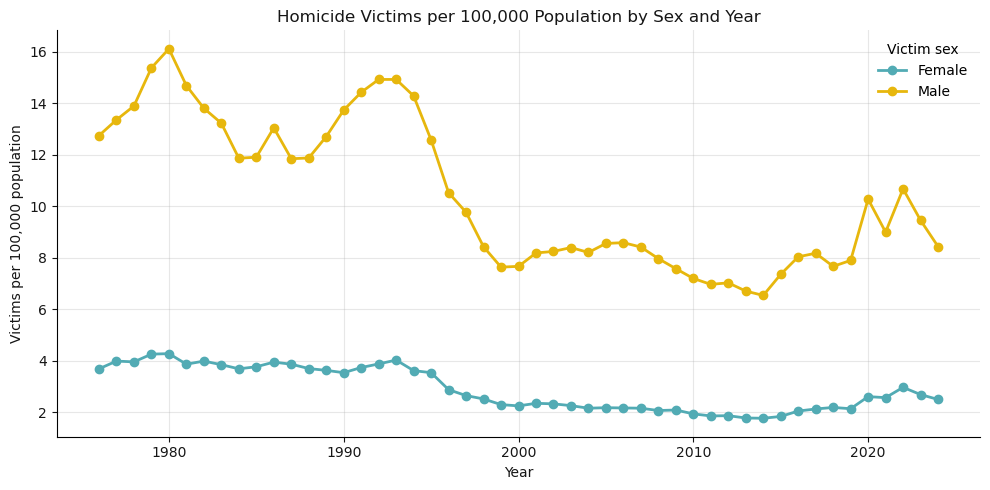

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

FILE = "shr_victims_clean.csv"
POP_FILE = "population_state_year.csv"
YEAR_COL = "year"
SEX_COL = "victim_sex"
STATE_COL = "state"

POP_STATE_COL = "state_abb"
POP_YEAR_COL = "year"
POP_FEMALE_COL = "pop_female"
POP_MALE_COL = "pop_male"
PER = 100_000

GOLD = "#e7b70d"
TEAL = "#52abb4"
NEAR_BLACK = "#161616"
WHITE = "#ffffff"

STATE_ABB = {
    "ALABAMA": "AL", "ALASKA": "AK", "ARIZONA": "AZ", "ARKANSAS": "AR", "CALIFORNIA": "CA",
    "COLORADO": "CO", "CONNECTICUT": "CT", "DELAWARE": "DE", "DISTRICT OF COLUMBIA": "DC",
    "FLORIDA": "FL", "GEORGIA": "GA", "HAWAII": "HI", "IDAHO": "ID", "ILLINOIS": "IL",
    "INDIANA": "IN", "IOWA": "IA", "KANSAS": "KS", "KENTUCKY": "KY", "LOUISIANA": "LA",
    "MAINE": "ME", "MARYLAND": "MD", "MASSACHUSETTS": "MA", "MICHIGAN": "MI", "MINNESOTA": "MN",
    "MISSISSIPPI": "MS", "MISSOURI": "MO", "MONTANA": "MT", "NEBRASKA": "NE", "NEVADA": "NV",
    "NEW HAMPSHIRE": "NH", "NEW JERSEY": "NJ", "NEW MEXICO": "NM", "NEW YORK": "NY",
    "NORTH CAROLINA": "NC", "NORTH DAKOTA": "ND", "OHIO": "OH", "OKLAHOMA": "OK", "OREGON": "OR",
    "PENNSYLVANIA": "PA", "RHODE ISLAND": "RI", "SOUTH CAROLINA": "SC", "SOUTH DAKOTA": "SD",
    "TENNESSEE": "TN", "TEXAS": "TX", "UTAH": "UT", "VERMONT": "VT", "VIRGINIA": "VA",
    "WASHINGTON": "WA", "WEST VIRGINIA": "WV", "WISCONSIN": "WI", "WYOMING": "WY",
}

sex_map = {
    "male": "Male", "m": "Male", "man": "Male",
    "female": "Female", "f": "Female", "woman": "Female",
}

df = pd.read_csv(FILE, low_memory=False)
df["sex_group"] = df[SEX_COL].astype("string").str.strip().str.lower().map(sex_map)
df[YEAR_COL] = pd.to_numeric(df[YEAR_COL], errors="coerce")
df[STATE_COL] = df[STATE_COL].astype("string").str.strip().str.upper().map(STATE_ABB)
df = df.dropna(subset=[YEAR_COL, "sex_group", STATE_COL])
df[YEAR_COL] = df[YEAR_COL].astype(int)

pop = pd.read_csv(POP_FILE, low_memory=False)
pop = pop.rename(columns={POP_STATE_COL: STATE_COL, POP_YEAR_COL: YEAR_COL})
pop[STATE_COL] = pop[STATE_COL].astype("string").str.strip().str.upper()
pop[YEAR_COL] = pd.to_numeric(pop[YEAR_COL], errors="coerce")
pop = pop.dropna(subset=[YEAR_COL])
pop[YEAR_COL] = pop[YEAR_COL].astype(int)

missing = sorted(set(df[STATE_COL].dropna()) - set(pop[STATE_COL].dropna()))
if missing:
    print("Victim states not in population file (excluded):", missing)
df = df[df[STATE_COL].isin(pop[STATE_COL])]

pop_long = pop.melt(
    id_vars=[STATE_COL, YEAR_COL],
    value_vars=[POP_FEMALE_COL, POP_MALE_COL],
    var_name="sex_group",
    value_name="population",
)
pop_long["sex_group"] = pop_long["sex_group"].map({POP_FEMALE_COL: "Female", POP_MALE_COL: "Male"})
pop_long["population"] = pd.to_numeric(pop_long["population"], errors="coerce")

victims = (
    df.groupby([YEAR_COL, "sex_group"]).size()
      .unstack(fill_value=0)
      .reindex(columns=["Female", "Male"], fill_value=0)
)
popn = (
    pop_long.groupby([YEAR_COL, "sex_group"])["population"].sum()
      .unstack()
      .reindex(columns=["Female", "Male"])
)

years = victims.index.intersection(popn.index).sort_values()
victims = victims.loc[years]
popn = popn.loc[years]
rates = (victims / popn * PER).round(2)

summary = pd.DataFrame({
    "Female victims": victims["Female"],
    "Male victims": victims["Male"],
    "Female per 100k": rates["Female"],
    "Male per 100k": rates["Male"],
})
print(summary)

fig, ax = plt.subplots(figsize=(10, 5), facecolor=WHITE)
ax.set_facecolor(WHITE)
ax.plot(rates.index, rates["Female"], marker="o", color=TEAL, lw=2, label="Female")
ax.plot(rates.index, rates["Male"], marker="o", color=GOLD, lw=2, label="Male")
ax.set(
    title="Homicide Victims per 100,000 Population by Sex and Year",
    xlabel="Year",
    ylabel="Victims per 100,000 population",
)
for item in [ax.title, ax.xaxis.label, ax.yaxis.label]:
    item.set_color(NEAR_BLACK)
ax.tick_params(colors=NEAR_BLACK)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.grid(alpha=0.3)
ax.legend(title="Victim sex", frameon=False)
plt.tight_layout()
plt.show()

Definition:

Femicide : As per UN, femicide (also called feminicide) is the intentional killing of women or girls because of their gender. Unlike the general term homicide, femicide highlights gender-based motivations, unequal power dynamics, and systemic discrimination.

###Analysis_2
Comparing gender based violence by their intimate partners.

Victims with known relationship, 1976-2024: 517,827
            total  intimate   pct
sex_group                        
Female     131825     57704  43.8
Male       386002     26516   6.9


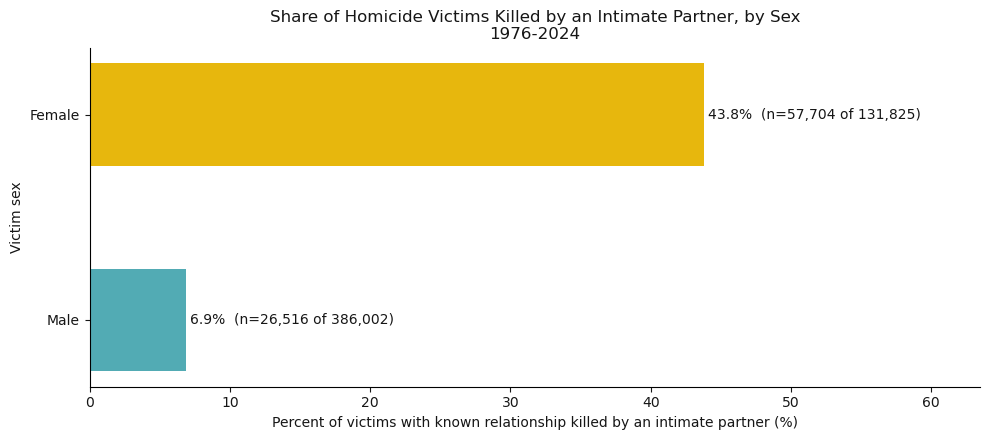

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

FILE = "shr_victims_clean.csv"
SEX_COL = "victim_sex"
REL_COL = "relation_to_offender_1"
INTIMATE_PATTERN = r"intimate|spouse|husband|wife|boyfriend|girlfriend"
YEAR_MIN, YEAR_MAX = 1976, 2024

GOLD = "#e7b70d"
TEAL = "#52abb4"
NEAR_BLACK = "#161616"
WHITE = "#ffffff"

sex_map = {
    "male": "Male", "m": "Male", "man": "Male",
    "female": "Female", "f": "Female", "woman": "Female",
}

df = pd.read_csv(FILE, low_memory=False, usecols=["year", SEX_COL, REL_COL])
df["year"] = pd.to_numeric(df["year"], errors="coerce")
df = df[df["year"].between(YEAR_MIN, YEAR_MAX)].copy()
df["sex_group"] = df[SEX_COL].astype("string").str.strip().str.lower().map(sex_map)
df = df.dropna(subset=["sex_group"]).copy()

rel = df[REL_COL].fillna("").astype(str).str.strip()
known = rel.ne("") & ~rel.str.contains("unknown", case=False)
df = df[known].copy()
df["intimate"] = rel[known].str.contains(INTIMATE_PATTERN, case=False, regex=True)

summary = (
    df.groupby("sex_group")["intimate"]
      .agg(total="size", intimate="sum")
      .reindex(["Female", "Male"])
)
summary["pct"] = summary["intimate"] / summary["total"] * 100
print(f"Victims with known relationship, {YEAR_MIN}-{YEAR_MAX}: {len(df):,}")
print(summary.round(1).to_string())

fig, ax = plt.subplots(figsize=(10, 4.5), facecolor=WHITE)
ax.set_facecolor(WHITE)
bars = ax.barh(summary.index, summary["pct"], color=[GOLD, TEAL], height=0.5)
ax.invert_yaxis()
for bar, (_, r) in zip(bars, summary.iterrows()):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2,
            f"{r['pct']:.1f}%  (n={int(r['intimate']):,} of {int(r['total']):,})",
            va="center", ha="left", color=NEAR_BLACK)
ax.set_xlim(0, summary["pct"].max() * 1.45)
ax.set(
    title=f"Share of Homicide Victims Killed by an Intimate Partner, by Sex\n{YEAR_MIN}-{YEAR_MAX}",
    xlabel="Percent of victims with known relationship killed by an intimate partner (%)",
    ylabel="Victim sex",
)
for item in [ax.title, ax.xaxis.label, ax.yaxis.label]:
    item.set_color(NEAR_BLACK)
ax.tick_params(colors=NEAR_BLACK)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.savefig("intimate_partner_share_by_sex.png", dpi=150, facecolor=WHITE)
plt.show()

Explaination: 
The chart compares how often women and men are killed by an intimate partner, among victims whose relationship to the offender is known, from 1976 to 2024.

Female victims: 43.8% (57,704 of 131,825) were killed by an intimate partner.
Male victims: 6.9% (26,516 of 386,002) were killed by an intimate partner.
So an intimate partner was the offender in about 44 of every 100 female homicides with a known relationship, compared with about 7 of every 100 male homicides.

###Analysis_3

Gender and age-based intimate partner violence 

Victims by age and sex:
sex_group  Female  Male
age_group              
Under 18     1114   131
18-29       18091  6176
30-39       16712  7994
40-49       10952  6059
50-59        5166  3629
60+          5365  2365


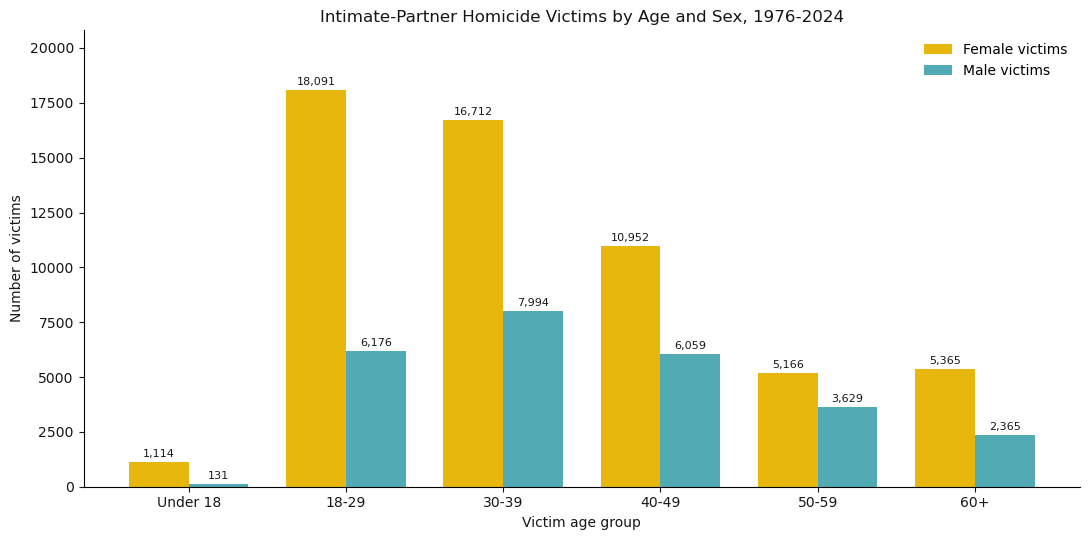

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FILE = "shr_victims_clean.csv"
YEAR_MIN, YEAR_MAX = 1976, 2024
INTIMATE_PATTERN = r"intimate|spouse|husband|wife|boyfriend|girlfriend"
BINS = [0, 17, 29, 39, 49, 59, 120]
LABELS = ["Under 18", "18-29", "30-39", "40-49", "50-59", "60+"]

GOLD = "#e7b70d"
TEAL = "#52abb4"
NEAR_BLACK = "#161616"
WHITE = "#ffffff"

df = pd.read_csv(FILE, low_memory=False,
                 usecols=["year", "victim_sex", "relation_to_offender_1",
                          "victim_age_raw", "victim_age"])
df["year"] = pd.to_numeric(df["year"], errors="coerce")
df = df[df["year"].between(YEAR_MIN, YEAR_MAX)].copy()

sex = df["victim_sex"].astype("string").str.strip().str.lower()
df["sex_group"] = np.select(
    [sex.isin(["female", "f", "woman"]), sex.isin(["male", "m", "man"])],
    ["Female", "Male"], default="")

rel = df["relation_to_offender_1"].fillna("").astype(str).str.strip()
known = rel.ne("") & ~rel.str.contains("unknown", case=False)
df = df[known & df["sex_group"].ne("")].copy()
df["intimate"] = rel[df.index].str.contains(INTIMATE_PATTERN, case=False, regex=True)
ip = df[df["intimate"]].copy()

ip["age"] = pd.to_numeric(ip["victim_age_raw"], errors="coerce").fillna(
    pd.to_numeric(ip["victim_age"], errors="coerce"))
ip = ip.dropna(subset=["age"])
ip["age_group"] = pd.cut(ip["age"], BINS, labels=LABELS)

counts = (ip.groupby(["age_group", "sex_group"], observed=False).size()
            .unstack(fill_value=0)
            .reindex(index=LABELS, columns=["Female", "Male"], fill_value=0))
print("Victims by age and sex:")
print(counts.to_string())

x = np.arange(len(LABELS))
w = 0.38
fig, ax = plt.subplots(figsize=(11, 5.5), facecolor=WHITE)
ax.set_facecolor(WHITE)

b1 = ax.bar(x - w / 2, counts["Female"], w, color=GOLD, label="Female victims")
b2 = ax.bar(x + w / 2, counts["Male"], w, color=TEAL, label="Male victims")
for bars, col in [(b1, "Female"), (b2, "Male")]:
    for bar, n in zip(bars, counts[col]):
        ax.text(bar.get_x() + bar.get_width() / 2, n + 150, f"{n:,}",
                ha="center", va="bottom", color=NEAR_BLACK, fontsize=8)

ax.set_xticks(x, LABELS)
ax.set_ylim(0, counts.values.max() * 1.15)
ax.set(title=f"Intimate-Partner Homicide Victims by Age and Sex, {YEAR_MIN}-{YEAR_MAX}",
       xlabel="Victim age group", ylabel="Number of victims")
for item in [ax.title, ax.xaxis.label, ax.yaxis.label]:
    item.set_color(NEAR_BLACK)
ax.tick_params(colors=NEAR_BLACK)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("intimate_partner_age_counts_by_sex.png", dpi=150, facecolor=WHITE)
plt.show()

Explaination:

This chart shows the number of intimate-partner homicide victims in each age group, for women (gold) and men (teal), 1976–2024. Bars show counts, not rates, so they reflect both how many people were killed and how many people are in each age group.
What the chart shows

Women outnumber men in every age group except under 18. The gap is widest at 18–29 (18,091 women vs. 6,176 men) and 30–39 (16,712 vs. 7,994).
Most victims are between 18 and 49. Women's counts peak at 18–29 and 30–39, then fall after 40–49. For women, the 60+ group (5,365) is higher than 50–59 (5,166).
Under 18 is small for both sexes (1,114 women, 131 men).

What the chart cannot tell you

Which group is more at risk. Counts rise and fall with population size, so a large group can have many victims without being more vulnerable. The rate chart, which divides by population for each sex and age group, is the right measure for that question.
Whether men or women are more often killed by partners. The bars are different totals, so compare the rate version instead.

Caveats

These are reported SHR cases with a known intimate-partner relationship. Unknown relationships are excluded, so the true counts may be higher.
Coverage of SHR reporting has changed over 1976–2024, which affects counts across decades.
The chart pools all years, so it doesn't show whether the age pattern has shifted over time.

###Analysis_4
Relationship trends with female victims

/var/folders/13/n8t83n797vnb_knw4rhjyzlm0000gn/T/ipykernel_2107/2486047609.py:36: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  f["group"] = np.select([f["rel"].str.contains(p, regex=True) for p in GROUPS.values()],


Female victims, male offenders, known relationship: 115,573
group
Intimate partner                               57327
Other family                                   14901
Acquaintance, friend, neighbor, other known    30596
Stranger                                       12749
Unclassified                                       0

Labels by group (check grouping):
group                                        rel                       
Acquaintance, friend, neighbor, other known  victim was acquaintance       19201
                                             victim was otherwise known     6267
                                             victim was friend              3314
                                             victim was neighbor            1644
                                             victim was employer             102
                                             victim was employee              68
Intimate partner                             victim was wife               2

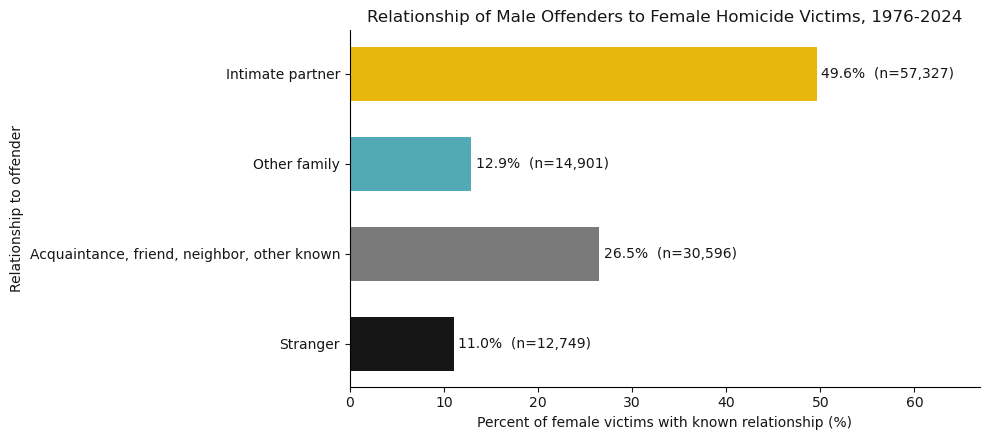

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FILE = "shr_victims_clean.csv"
YEAR_MIN, YEAR_MAX = 1976, 2024

GOLD = "#e7b70d"
TEAL = "#52abb4"
NEAR_BLACK = "#161616"
WHITE = "#ffffff"

GROUPS = {
    "Intimate partner": r"wife|husband|girlfriend|boyfriend|intimate|spouse|homosexual",
    "Other family": r"\b(family|son|daughter|brother|sister|father|mother|in-law|stepfather|stepmother|stepson|stepdaughter)\b",
    "Acquaintance, friend, neighbor, other known": r"acquaintance|friend|neighbor|otherwise known|employ",
    "Stranger": r"stranger",
}
COLORS = {
    "Intimate partner": GOLD,
    "Other family": TEAL,
    "Acquaintance, friend, neighbor, other known": "#7a7a7a",
    "Stranger": NEAR_BLACK,
}

df = pd.read_csv(FILE, low_memory=False,
                 usecols=["year", "victim_sex", "offender_1_sex", "relation_to_offender_1"])
df = df[df["year"].between(YEAR_MIN, YEAR_MAX)].copy()
df["rel"] = df["relation_to_offender_1"].astype(str).str.lower().str.strip()

sex = df["victim_sex"].astype(str).str.lower().str.strip()
off = df["offender_1_sex"].astype(str).str.lower().str.strip()
known = df["rel"].ne("nan") & df["rel"].ne("") & ~df["rel"].str.contains("unknown")
f = df[sex.isin(["female", "f", "woman"]) & off.isin(["male", "m"]) & known].copy()

f["group"] = np.select([f["rel"].str.contains(p, regex=True) for p in GROUPS.values()],
                       list(GROUPS), default="Unclassified")

counts = f["group"].value_counts().reindex(list(GROUPS) + ["Unclassified"], fill_value=0)
print(f"Female victims, male offenders, known relationship: {counts.sum():,}")
print(counts.to_string())
print("\nLabels by group (check grouping):")
print(f.groupby("group")["rel"].value_counts().groupby(level=0).head(6).to_string())

groups = list(GROUPS)
n = counts[groups][::-1]
pct = n / counts[groups].sum() * 100
colors = [COLORS[g] for g in pct.index]

fig, ax = plt.subplots(figsize=(10, 4.5), facecolor=WHITE)
ax.set_facecolor(WHITE)
bars = ax.barh(pct.index, pct.values, color=colors, height=0.6)
for bar, p, c in zip(bars, pct.values, n.values):
    ax.text(p + 0.5, bar.get_y() + bar.get_height() / 2, f"{p:.1f}%  (n={c:,})",
            va="center", color=NEAR_BLACK)
ax.set_xlim(0, pct.max() * 1.35)
ax.set(title=f"Relationship of Male Offenders to Female Homicide Victims, {YEAR_MIN}-{YEAR_MAX}",
       xlabel="Percent of female victims with known relationship (%)",
       ylabel="Relationship to offender")
for item in [ax.title, ax.xaxis.label, ax.yaxis.label]:
    item.set_color(NEAR_BLACK)
ax.tick_params(colors=NEAR_BLACK)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.savefig("female_victim_male_offender_relationship.png", dpi=150, facecolor=WHITE)
plt.show()

The chart shows how female homicide victims killed by male offenders were related to the offender, among cases with a known relationship, from 1976 to 2024.

Intimate partner: 49.6% (57,327 victims). About half of these cases involved a current or former partner.
Acquaintance, friend, neighbor, or other known: 26.5% (30,596). This is the second-largest group.
Other family: 12.9% (14,901). Relatives such as sons, fathers, or in-laws.
Stranger: 11.0% (12,749).
The bars are shares of known cases only, so they sum to 100%. Cases with an unknown relationship are excluded, which is a large share of the file, so the true distribution could differ.

###Analysis_5

Age-wise heatmap of female victims killed by male offenders, with known relationship, by year and age group.

Female victims killed by male intimate partners, known ages: 56,427

Row percentages (offender age within each victim age group):
offender_group  Under 18  18-29  30-39  40-49  50-59   60+
victim_group                                              
Under 18            25.1   67.4    5.3    1.6    0.3   0.4
18-29                0.7   59.9   30.2    7.0    1.8   0.5
30-39                0.0   11.3   51.6   28.4    6.9   1.8
40-49                0.0    3.3   16.1   49.4   25.4   5.8
50-59                0.0    1.3    5.0   17.5   50.3  25.8
60+                  0.0    0.2    0.8    3.0    8.7  87.3


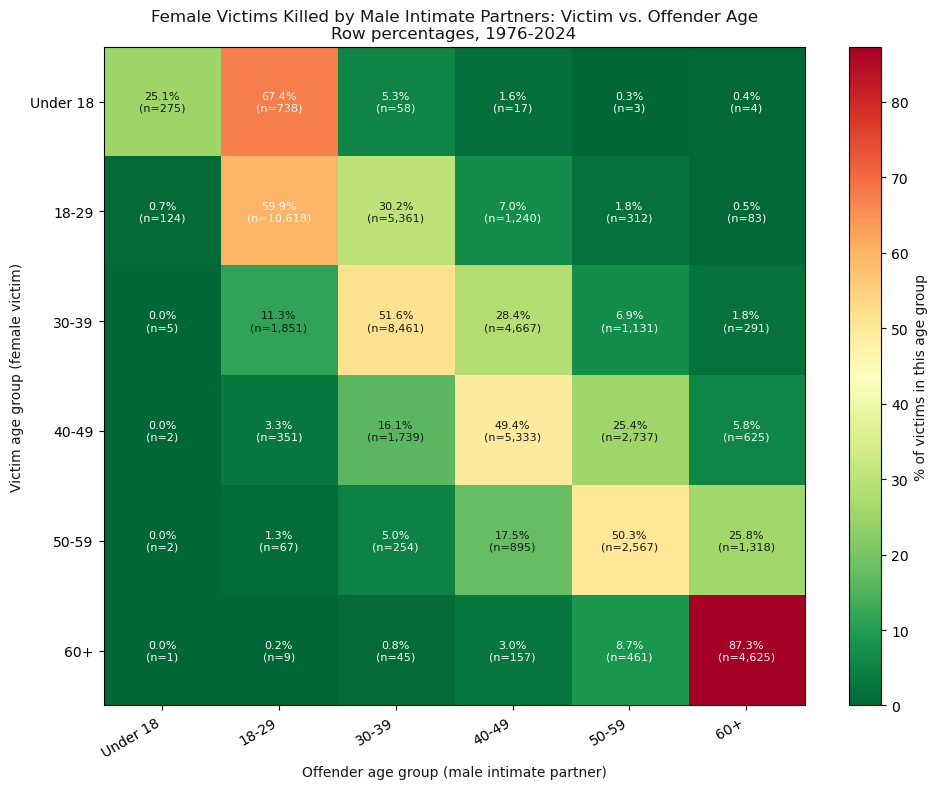

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

FILE = "shr_victims_clean.csv"
YEAR_MIN, YEAR_MAX = 1976, 2024
INTIMATE_PATTERN = r"intimate|spouse|husband|wife|boyfriend|girlfriend"
BINS = [0, 17, 29, 39, 49, 59, 120]
LABELS = ["Under 18", "18-29", "30-39", "40-49", "50-59", "60+"]
NEAR_BLACK = "#161616"
WHITE = "#ffffff"

df = pd.read_csv(FILE, low_memory=False,
                 usecols=["year", "victim_sex", "offender_1_sex", "relation_to_offender_1",
                          "victim_age_raw", "victim_age", "offender_1_age"])
df["year"] = pd.to_numeric(df["year"], errors="coerce")
df = df[df["year"].between(YEAR_MIN, YEAR_MAX)].copy()

sex = df["victim_sex"].astype("string").str.strip().str.lower()
off = df["offender_1_sex"].astype("string").str.strip().str.lower()
rel = df["relation_to_offender_1"].fillna("").astype(str).str.strip()
intimate = rel.str.contains(INTIMATE_PATTERN, case=False, regex=True)

f = df[sex.isin(["female", "f", "woman"]) & off.isin(["male", "m"]) & intimate].copy()

f["v_age"] = pd.to_numeric(f["victim_age_raw"], errors="coerce").fillna(
    pd.to_numeric(f["victim_age"], errors="coerce"))
f["o_age"] = pd.to_numeric(f["offender_1_age"], errors="coerce")
f = f.dropna(subset=["v_age", "o_age"])
f["victim_group"] = pd.cut(f["v_age"], BINS, labels=LABELS)
f["offender_group"] = pd.cut(f["o_age"], BINS, labels=LABELS)
f = f.dropna(subset=["victim_group", "offender_group"])

ct = (pd.crosstab(f["victim_group"], f["offender_group"])
        .reindex(index=LABELS, columns=LABELS, fill_value=0))
pct = ct.div(ct.sum(axis=1), axis=0) * 100

print(f"Female victims killed by male intimate partners, known ages: {ct.values.sum():,}")
print("\nRow percentages (offender age within each victim age group):")
print(pct.round(1).to_string())

fig, ax = plt.subplots(figsize=(10, 8), facecolor=WHITE)
ax.set_facecolor(WHITE)
im = ax.imshow(pct.values, cmap="RdYlGn_r", norm=Normalize(vmin=0, vmax=pct.values.max()),
               aspect="auto")
ax.set_xticks(range(len(LABELS)), labels=LABELS, rotation=30, ha="right")
ax.set_yticks(range(len(LABELS)), labels=LABELS)

vmax = pct.values.max()
for i in range(len(LABELS)):
    for j in range(len(LABELS)):
        v = pct.values[i, j]
        text_color = WHITE if v > 0.6 * vmax or v < 0.1 * vmax else NEAR_BLACK
        ax.text(j, i, f"{v:.1f}%\n(n={ct.values[i, j]:,})", ha="center", va="center",
                fontsize=8, color=text_color)

ax.set(xlabel="Offender age group (male intimate partner)",
       ylabel="Victim age group (female victim)",
       title=f"Female Victims Killed by Male Intimate Partners: Victim vs. Offender Age\n"
             f"Row percentages, {YEAR_MIN}-{YEAR_MAX}")
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("% of victims in this age group")
for item in [ax.title, ax.xaxis.label, ax.yaxis.label, cbar.ax.yaxis.label]:
    item.set_color(NEAR_BLACK)
plt.tight_layout()
plt.savefig("female_victim_intimate_partner_age_heatmap.png", dpi=150, facecolor=WHITE)
plt.show()

Explaination:

This heatmap shows the age of the male intimate partner (columns) for each age group of female victims (rows). Each row sums to 100%, so read across a row to see the partner-age mix for that victim age group. Red cells are the most common pairings, and green cells are the least common.
Main pattern: partners are usually in the same age band as the victim
The diagonal cells, where the victim and partner are in the same age group, are the largest or near-largest in most rows:

18-29 victims: 59.9% had partners aged 18-29, and 30.2% had partners aged 30-39.
30-39 victims: 51.6% had partners aged 30-39, and 28.4% had partners aged 40-49.
40-49 victims: 49.4% had partners aged 40-49, and 25.4% had partners aged 50-59.
50-59 victims: 50.3% had partners aged 50-59, and 25.8% had partners aged 60+.
60+ victims: 87.3% had partners aged 60+, the strongest concentration in the chart.

Partners are often a bit older
Off the diagonal, the cells just above and to the right of the diagonal are the next largest in most rows. Victims tend to be paired with partners in their own age band or a slightly older one. A 30-39 victim is more often killed by a 40-49 partner (28.4%) than by a 20-29 partner (11.3%).
Under 18 victims
Most cases in this row (67.4%) involve partners aged 18-29, and 25.1% involve partners under 18. The under-18 row is small (n = 1,095 in total), so treat these percentages as unstable. Some partners under 18 may also reflect teen relationships or coding issues.
Caveats

These are shares within each victim age group, not rates. A large share in one cell can reflect how many people are in those age groups, not a higher risk for that pairing.
The 60+ victim row and the under-18 row are dominated by a few cells, so their percentages move a lot with small changes in count. Check the n values before drawing conclusions.
Cases with unknown victim or offender age are excluded.
The data describe reported SHR cases, and SHR coverage has changed over 1976–2024.

###Analysis_6


National Femicide Trend With Major Events in US

Typical year-to-year change (median absolute): 3.3%

                        event  start  pre_rate  post_rate  change_pct
          VAWA and Brady Act   1994     2.549      2.232       -12.4
        Lautenberg Amendment   1996     2.494      1.804       -27.7
 Assault weapons ban expires   2004     1.635      1.563        -4.4
             Great Recession   2008     1.572      1.503        -4.4
Affordable Care Act coverage   2014     1.389      1.398         0.7
           COVID-19 pandemic   2020     1.510      1.965        30.2
              Dobbs decision   2022     1.737      2.009        15.6
Compare each change_pct with the typical year-to-year change above.


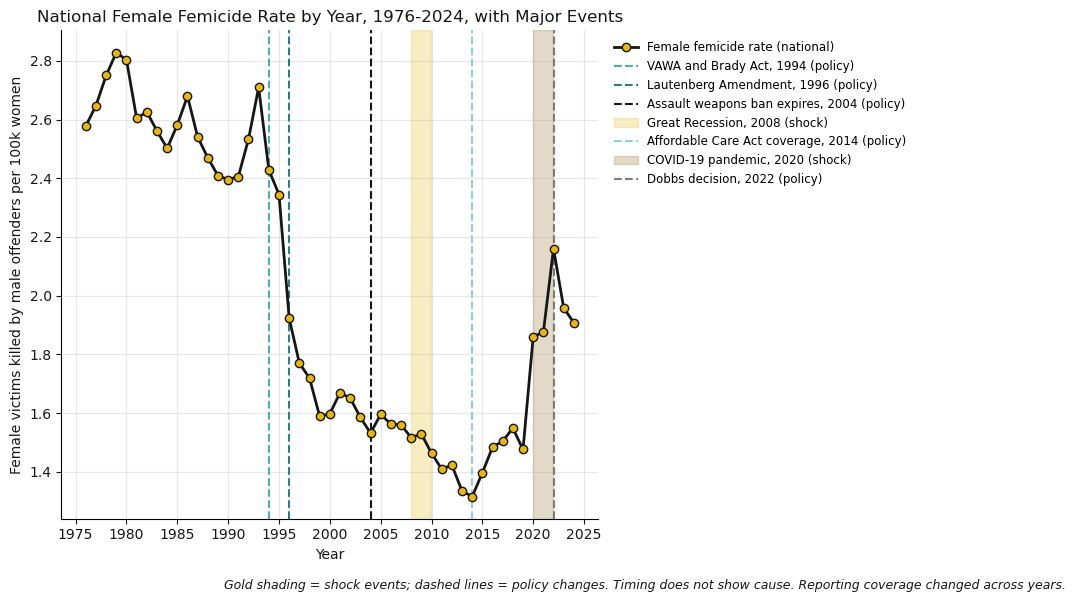

Saved: national_femicide_events.png | Saved: national_femicide_by_year.csv


In [21]:
import pandas as pd
import matplotlib.pyplot as plt

SHR_FILE = "shr_victims_clean.csv"
POP_FILE = "population_state_year.csv"
OUT_PNG = "national_femicide_events.png"
OUT_CSV = "national_femicide_by_year.csv"
YEAR_MIN, YEAR_MAX = 1976, 2024
WINDOW = 3

GOLD = "#e7b70d"
NEAR_BLACK = "#161616"
WHITE = "#ffffff"

# (label, start year, kind, color)
EVENTS = [
    ("VAWA and Brady Act", 1994, "policy", "#52abb4"),
    ("Lautenberg Amendment", 1996, "policy", "#2e7d86"),
    ("Assault weapons ban expires", 2004, "policy", "#161616"),
    ("Great Recession", 2008, "shock", GOLD),
    ("Affordable Care Act coverage", 2014, "policy", "#8fd0d6"),
    ("COVID-19 pandemic", 2020, "shock", "#8c6d1f"),
    ("Dobbs decision", 2022, "policy", "#7a7a7a"),
]

# ---------- Data ----------
shr = pd.read_csv(SHR_FILE, low_memory=False, usecols=["year", "victim_sex", "offender_1_sex"])
shr["year"] = pd.to_numeric(shr["year"], errors="coerce")
shr = shr[shr["year"].between(YEAR_MIN, YEAR_MAX)].copy()
shr["year"] = shr["year"].astype(int)
sex = shr["victim_sex"].astype("string").str.strip().str.lower()
off = shr["offender_1_sex"].astype("string").str.strip().str.lower()
victims = (shr[sex.isin(["female", "f", "woman"]) & off.isin(["male", "m"])]
           .groupby("year").size().rename("victims"))

pop = pd.read_csv(POP_FILE, low_memory=False, usecols=["year", "pop_female"])
pop["year"] = pd.to_numeric(pop["year"], errors="coerce").astype(int)
pop_f = pop.groupby("year")["pop_female"].sum().rename("pop_female")

years = list(range(YEAR_MIN, YEAR_MAX + 1))
nat = pd.concat([victims, pop_f], axis=1).reindex(years)
nat["rate"] = nat["victims"] / nat["pop_female"] * 100_000
nat.to_csv(OUT_CSV)

typical = nat["rate"].pct_change().abs().median() * 100
print(f"Typical year-to-year change (median absolute): {typical:.1f}%")

rows = []
for label, start, kind, _ in EVENTS:
    pre = nat.loc[start - WINDOW:start - 1, "rate"]
    post = nat.loc[start:start + WINDOW - 1, "rate"]
    if pre.notna().sum() == 0 or post.notna().sum() == 0:
        continue
    rows.append({"event": label, "start": start,
                 "pre_rate": round(pre.mean(), 3),
                 "post_rate": round(post.mean(), 3),
                 "change_pct": round((post.mean() / pre.mean() - 1) * 100, 1)})
print("\n", pd.DataFrame(rows).to_string(index=False))
print("Compare each change_pct with the typical year-to-year change above.")

# ---------- Plot ----------
fig, ax = plt.subplots(figsize=(13, 6), facecolor=WHITE)
ax.set_facecolor(WHITE)

for label, start, kind, color in EVENTS:
    if kind == "shock":
        ax.axvspan(start, start + 1.9, color=color, alpha=0.25, zorder=0,
                   label=f"{label}, {start} (shock)")
    else:
        ax.axvline(start, color=color, linestyle="--", linewidth=1.5, zorder=2,
                   label=f"{label}, {start} (policy)")

ax.plot(nat.index, nat["rate"], marker="o", color=NEAR_BLACK, lw=2,
        mfc=GOLD, mec=NEAR_BLACK, zorder=3, label="Female femicide rate (national)")

ax.set(title="National Female Femicide Rate by Year, 1976-2024, with Major Events",
       xlabel="Year", ylabel="Female victims killed by male offenders per 100k women")
ax.set_xticks(range(1975, 2026, 5))
ax.grid(alpha=0.3)
ax.tick_params(colors=NEAR_BLACK)
for item in [ax.title, ax.xaxis.label, ax.yaxis.label]:
    item.set_color(NEAR_BLACK)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)

# Legend: femicide line first, then events
handles, labels = ax.get_legend_handles_labels()
first = labels.index("Female femicide rate (national)")
order = [first] + [i for i in range(len(labels)) if i != first]
ax.legend([handles[i] for i in order], [labels[i] for i in order],
          fontsize=8.5, loc="upper left", bbox_to_anchor=(1.01, 1.0), frameon=False)

fig.text(0.5, 0.01,
         "Gold shading = shock events; dashed lines = policy changes. "
         "Timing does not show cause. Reporting coverage changed across years.",
         ha="center", fontsize=9, style="italic", color=NEAR_BLACK)
plt.tight_layout(rect=[0, 0.03, 0.72, 1])
plt.savefig(OUT_PNG, dpi=150, facecolor=WHITE)
plt.show()
print("Saved:", OUT_PNG, "| Saved:", OUT_CSV)

National Femicide Trend With Major Events in US

This chart shows the national female femicide rate from 1976 to 2024, meaning female victims killed by male offenders per 100,000 women. The vertical markers show major policy and social events. Gold shading marks shock events, and teal dashed lines mark federal policy changes.

Policy changes (teal dashed lines) The dashed lines mark the year each change took effect. They show timing only and do not establish that any change caused a shift in the femicide rate.

VAWA and Brady Act (1994): The Violence Against Women Act created federal funding and protections for domestic violence and sexual assault victims. The Brady Act required background checks for handgun purchases.
Lautenberg Amendment (1996): Barred people convicted of misdemeanor domestic violence from owning firearms.
Assault weapons ban expires (2004): The federal ban on certain semiautomatic assault weapons expired in September 2004 and was not renewed.
Affordable Care Act coverage (2014): The main coverage provisions took effect, including Medicaid expansion in participating states and marketplace subsidies.
Dobbs decision (2022): The U.S. Supreme Court overturned Roe v. Wade in June 2022, returning abortion regulation to the states.
Shock events (gold shading)

Great Recession (2008–2009): The rate barely changes, with a slight dip, so no clear recession effect appears.
COVID-19 pandemic (2020–2021): The rate rises from about 1.5 to about 2.2 by 2022, the highest value since the early 1990s. Part of this rise may reflect more agencies reporting to SHR.
Main pattern

1976–1980: The rate is high, around 2.6 to 2.8, then drifts down through the 1980s.
1993–2000: The rate falls sharply, from about 2.7 to about 1.6. This is the largest sustained decline in the series. The decline started before the 1994 and 1996 laws and was broad across many crimes, so those laws cannot be credited with it.
2000–2019: The rate stays fairly flat, mostly between 1.4 and 1.7.
2014: The rate reaches its lowest point, about 1.3.
2023–2024: The rate eases to about 1.9.
Caveats

SHR agency coverage changes by year, so the rate can move because of reporting, not only because of real change.
The rate uses all-age female population, which dilutes the rate for groups at highest risk.
Timing does not show cause. The chart describes the national pattern and cannot separate the effect of each event from other changes happening at the same time.

###Analysis_7

Means of Violence 

Female victims killed by male offenders, 1976-2024: 136,417
                                Count  Percent
category                                      
Unknown                         10006      7.3
Firearm                         74096     54.3
Sharp object                    22243     16.3
Blunt object or personal force  26677     19.6
Fire, poison, drugs, other       3395      2.5

Percent by period:
period                          1976-1999  2000-2024
category                                            
Unknown                               3.5       11.8
Firearm                              55.7       52.7
Sharp object                         17.0       15.5
Blunt object or personal force       21.4       17.4
Fire, poison, drugs, other            2.4        2.6


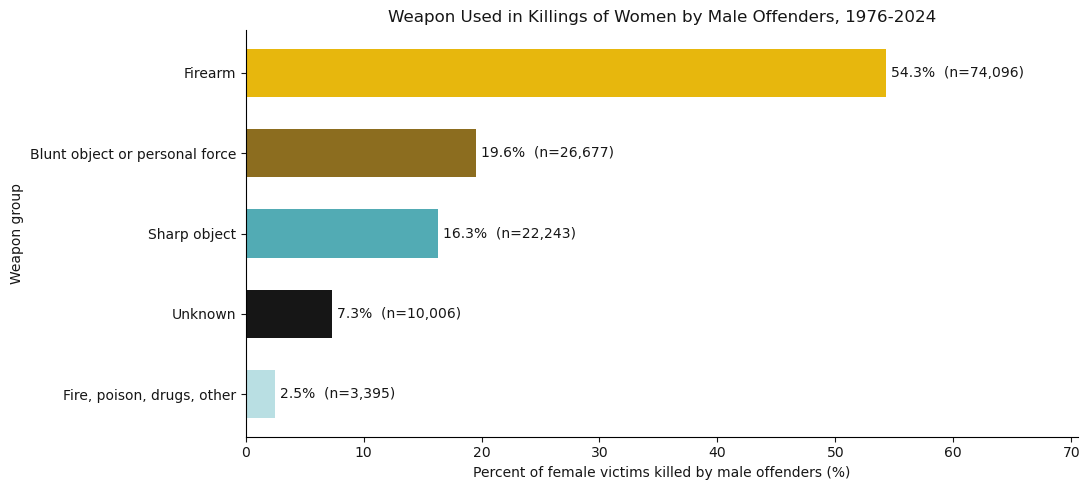

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FILE = "shr_victims_clean.csv"
YEAR_MIN, YEAR_MAX = 1976, 2024
WEAPON_COL = "offender_1_weapon"

NEAR_BLACK = "#161616"
WHITE = "#ffffff"

# Ordered rules: the first matching pattern sets the group
CATEGORIES = [
    ("Unknown", r"unknown|not reported"),
    ("Firearm", r"firearm|gun|handgun|rifle|shotgun"),
    ("Sharp object", r"knife|cutting|sharp|ice pick"),
    ("Blunt object or personal force", r"blunt|club|personal|hands|feet|strangul|asphyx|suffoc|drown"),
    ("Fire, poison, drugs, other", None),  # default for everything else
]
ORDER = [name for name, _ in CATEGORIES]
COLORS = {
    "Firearm": "#e7b70d",                         # gold
    "Sharp object": "#52abb4",                    # teal
    "Blunt object or personal force": "#8c6d1f",  # dark gold
    "Fire, poison, drugs, other": "#b9dfe3",      # light teal
    "Unknown": "#161616",                         # near-black
}

df = pd.read_csv(FILE, low_memory=False,
                 usecols=["year", "victim_sex", "offender_1_sex", WEAPON_COL])
df["year"] = pd.to_numeric(df["year"], errors="coerce")
df = df[df["year"].between(YEAR_MIN, YEAR_MAX)].copy()

sex = df["victim_sex"].astype("string").str.strip().str.lower()
off = df["offender_1_sex"].astype("string").str.strip().str.lower()
f = df[sex.isin(["female", "f", "woman"]) & off.isin(["male", "m"])].copy()

f["weapon_raw"] = f[WEAPON_COL].fillna("unknown").astype(str).str.strip().str.lower()
conds = [f["weapon_raw"].str.contains(p, regex=True) for _, p in CATEGORIES if p]
f["category"] = np.select(conds, ORDER[:-1], default=ORDER[-1])

counts = f["category"].value_counts().reindex(ORDER, fill_value=0)
pct = counts / counts.sum() * 100
print(f"Female victims killed by male offenders, {YEAR_MIN}-{YEAR_MAX}: {counts.sum():,}")
print(pd.DataFrame({"Count": counts, "Percent": pct.round(1)}).to_string())

f["period"] = np.where(f["year"] < 2000, "1976-1999", "2000-2024")
by_period = (pd.crosstab(f["category"], f["period"], normalize="columns") * 100).round(1)
print("\nPercent by period:")
print(by_period.reindex(ORDER, fill_value=0).to_string())

# Highest to lowest, top to bottom on the chart
plot_pct = pct.sort_values(ascending=True)
plot_counts = counts.loc[plot_pct.index]

fig, ax = plt.subplots(figsize=(11, 5), facecolor=WHITE)
ax.set_facecolor(WHITE)
bars = ax.barh(plot_pct.index, plot_pct.values,
               color=[COLORS[c] for c in plot_pct.index], height=0.6)
for bar, p, n in zip(bars, plot_pct.values, plot_counts.values):
    ax.text(p + 0.4, bar.get_y() + bar.get_height() / 2, f"{p:.1f}%  (n={n:,})",
            va="center", color=NEAR_BLACK)
ax.set_xlim(0, plot_pct.max() * 1.3)
ax.set(title=f"Weapon Used in Killings of Women by Male Offenders, {YEAR_MIN}-{YEAR_MAX}",
       xlabel="Percent of female victims killed by male offenders (%)",
       ylabel="Weapon group")
for item in [ax.title, ax.xaxis.label, ax.yaxis.label]:
    item.set_color(NEAR_BLACK)
ax.tick_params(colors=NEAR_BLACK)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.savefig("female_victim_weapon_share.png", dpi=150, facecolor=WHITE)
plt.show()

Explaination:

This chart shows the weapons used in killings of women by male offenders in the SHR data, 1976 to 2024 (136,417 cases). Each bar is that weapon group's share of all cases.

Firearm (54.3%, n=74,096): Over half of these killings involved a gun, including handguns, rifles, and shotguns. This is the largest group by far.
Blunt object or personal force (19.6%, n=26,677): This combines blunt objects with hands and feet, strangulation, asphyxiation, and drowning. It's the second-largest group, but it mixes several methods, so it's best read as a single category.
Sharp object (16.3%, n=22,243): Knives and other cutting instruments account for about one in six cases.
Unknown (7.3%, n=10,006): The weapon was recorded as unknown or not reported. This is shown separately so readers can see how much the picture depends on missing data.
Fire, poison, drugs, other (2.5%, n=3,395): Small categories, including fire, explosives, poison, and drugs.

Caveats

The weapon is recorded for the incident and linked to the first offender, so it describes how the killing was done, not the offender's background.
These shares cover reported cases only. Reporting coverage has changed over time, so compare periods with care.
The chart shows the mix of weapons, not the rate of killings, so it can't show whether firearm killings of women rose or fell per capita.
The 7.3% unknown share is large enough that the firearm and other shares could shift if weapon data were complete.